# DSC 411/511
# Rule Evaluation and Sequential Pattern Mining



---
# Section 0: Setup and Cleaning

In [ ]:
import jupyter_client.session as _s
from datetime import datetime, timezone
_s.utcnow = lambda: datetime.now(timezone.utc)

In [ ]:
import IPython
IPython.core.interactiveshell.InteractiveShell.showwarning = lambda *a, **k: None
!pip install mlxtend ucimlrepo --quiet

In [ ]:
import os, warnings, logging
os.environ['PYTHONWARNINGS'] = 'ignore'
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')
logging.getLogger('py.warnings').setLevel(logging.ERROR)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

pd.set_option('display.width', 220)
print('ready')

ready


In [ ]:
from ucimlrepo import fetch_ucirepo
retail = fetch_ucirepo(id=352)
raw = retail.data.original.copy()
print('raw shape:', raw.shape)
print()
print(raw.head(10).to_string())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


raw shape: (541909, 8)

  InvoiceNo StockCode                          Description  Quantity     InvoiceDate  UnitPrice  CustomerID         Country
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6  12/1/2010 8:26       2.55     17850.0  United Kingdom
1    536365     71053                  WHITE METAL LANTERN         6  12/1/2010 8:26       3.39     17850.0  United Kingdom
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8  12/1/2010 8:26       2.75     17850.0  United Kingdom
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6  12/1/2010 8:26       3.39     17850.0  United Kingdom
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6  12/1/2010 8:26       3.39     17850.0  United Kingdom
5    536365     22752         SET 7 BABUSHKA NESTING BOXES         2  12/1/2010 8:26       7.65     17850.0  United Kingdom
6    536365     21730    GLASS STAR FROSTED T-LIGHT HOLDER         6  12/1/2010 8:26       4.25     17850.0 

## 0.1 The data needs cleaning before anything else

Four problems in this file, and all four would corrupt the results.

In [ ]:
print('WHAT IS WRONG WITH THE RAW DATA')
print()
n0 = len(raw)
returns = raw['InvoiceNo'].astype(str).str.startswith('C').sum()
print(f'   rows                        {n0:>9,}')
print(f'   returns (invoice starts C)  {returns:>9,}   quantity is negative')
print(f'   missing CustomerID          {raw.CustomerID.isna().sum():>9,}   '
      f'({raw.CustomerID.isna().mean()*100:.1f}%)')
print(f'   missing Description         {raw.Description.isna().sum():>9,}')
print(f'   duplicate rows              {raw.duplicated().sum():>9,}')

WHAT IS WRONG WITH THE RAW DATA

   rows                          541,909
   returns (invoice starts C)      9,288   quantity is negative
   missing CustomerID            135,080   (24.9%)
   missing Description             1,454
   duplicate rows                  5,268


* Four separate problems, and all four would corrupt the results.
*  9,288 rows are returns. Their invoice number starts with a C and the quantity is negative. Leaving them in would count a refund as a purchase.
* 135,080 rows have no customer attached, a quarter of the file. That is fine for baskets but fatal for timelines.
* 1,454 rows have no product name, so we cannot say what was bought.
* 5,268 rows are exact duplicates of another row.

In [ ]:
df = raw.copy()
df['InvoiceNo'] = df['InvoiceNo'].astype(str)

df = df[~df['InvoiceNo'].str.startswith('C')]          # drop returns
df = df.dropna(subset=['Description'])                  # need a product name
df = df[df['Quantity'] > 0]                             # positive quantities only
df['Description'] = df['Description'].astype(str).str.strip().str.upper()
df = df.drop_duplicates()

print(f'rows after cleaning : {len(df):,}   (dropped {len(raw)-len(df):,})')
print(f'invoices            : {df.InvoiceNo.nunique():,}')
print(f'products            : {df.Description.nunique():,}')
print(f'customers (known)   : {int(df.CustomerID.nunique()):,}')
print()
print('NOTE: CustomerID is still missing on some rows. That is fine for baskets,')
print('      but Section 7 needs it, so we drop those rows there and not here.')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


rows after cleaning : 525,462   (dropped 16,447)
invoices            : 20,136
products            : 4,060
customers (known)   : 4,339

NOTE: CustomerID is still missing on some rows. That is fine for baskets,
      but Section 7 needs it, so we drop those rows there and not here.


---
# Section 1: Baskets

Group by InvoiceNo. Each invoice becomes one basket.

In [ ]:
baskets = (df.groupby('InvoiceNo')['Description']
             .apply(lambda s: sorted(set(s)))
             .tolist())
baskets = [b for b in baskets if 2 <= len(b) <= 40]

print(f'{len(baskets):,} baskets')
print(f'average basket size: {np.mean([len(b) for b in baskets]):.1f} products')
print()
print('Three baskets:')
for b in baskets[:3]:
    print('   ' + ', '.join(b[:6]) + (' ...' if len(b) > 6 else ''))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


15,266 baskets
average basket size: 15.4 products

Three baskets:
   CREAM CUPID HEARTS COAT HANGER, GLASS STAR FROSTED T-LIGHT HOLDER, KNITTED UNION FLAG HOT WATER BOTTLE, RED WOOLLY HOTTIE WHITE HEART., SET 7 BABUSHKA NESTING BOXES, WHITE HANGING HEART T-LIGHT HOLDER ...
   HAND WARMER RED POLKA DOT, HAND WARMER UNION JACK
   ASSORTED COLOUR BIRD ORNAMENT, BOX OF 6 ASSORTED COLOUR TEASPOONS, BOX OF VINTAGE ALPHABET BLOCKS, BOX OF VINTAGE JIGSAW BLOCKS, DOORMAT NEW ENGLAND, FELTCRAFT PRINCESS CHARLOTTE DOLL ...


* We group by invoice number, so every receipt becomes one basket.
* 15,266 baskets, averaging 15.4 products each.
* That is a large basket because this is a wholesaler, not a corner shop.
* Look at the variation. The second example has only two items, both hand warmers. The first and third have six or more.

In [ ]:
# keep the most common products, or the matrix will not fit in memory
TOP_N = 100          # lower this to 60 or 80 if later cells run slowly
common = df.Description.value_counts().head(TOP_N).index
baskets_small = [[p for p in b if p in set(common)] for b in baskets]
baskets_small = [b for b in baskets_small if len(b) >= 2]

te = TransactionEncoder()
B = pd.DataFrame(te.fit_transform(baskets_small), columns=te.columns_)
print(f'{B.shape[0]:,} baskets, {B.shape[1]} products (top {TOP_N} only)')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


9,938 baskets, 100 products (top 100 only)


* 4,060 products is too many. The matrix would be 15,000 rows by 4,060 columns and would not fit in memory.
* So we keep only the 100 most frequently sold products.
* That leaves 9,938 baskets, because some baskets contained none of the top 100.
* Worth noticing: we just discarded 3,960 products and a third of the baskets. A rare product can now never appear in a rule, so this filter decided what we can find before we mined anything.

### Two settings that control how long this takes

**MIN_SUPPORT** sets how common a combination must be. Halve it and the number of
itemsets can grow by an order of magnitude.

**MAX_LEN** caps how many products an itemset may contain. Without it, the algorithm
keeps building 5, 6 and 7-product combinations that nobody will ever read. Capping at
3 removes most of the work and loses nothing you would have used.



In [ ]:
import time

MIN_SUPPORT = 0.02          # raise this if the cell is slow
MAX_LEN     = 3             # longest itemset to build. 2 or 3 is plenty

t0 = time.perf_counter()
fi = fpgrowth(B, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
print(f'frequent itemsets : {len(fi):,}      ({time.perf_counter()-t0:.1f}s)')

t0 = time.perf_counter()
rules = association_rules(fi, metric='confidence', min_threshold=0.05)
print(f'rules generated   : {len(rules):,}      ({time.perf_counter()-t0:.1f}s)')

# filter FIRST, then build the label columns, so the slow string work
# only runs on the rules that survive
rules = rules[rules.consequents.apply(len) == 1].copy()
rules['IF']   = rules.antecedents.apply(lambda s: ' + '.join(sorted(s)))
rules['THEN'] = rules.consequents.apply(lambda s: list(s)[0])
print(f'one product on the right : {len(rules):,}')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


frequent itemsets : 145      (4.9s)
rules generated   : 100      (0.0s)
one product on the right : 94


* 145 frequent itemsets at 2 percent support, found in about 3 seconds.
* 2 percent of 9,938 baskets means a combination must appear in roughly 200 baskets to count.
* From those 145 itemsets we get 100 rules, of which 94 have a single product on the right side.
* 145 is a small number, and that is deliberate. A high threshold keeps only the genuinely common combinations.

In [ ]:
print('THE TEN MOST CONFIDENT RULES')
print()
top = rules.sort_values('confidence', ascending=False).head(10)
for _, r in top.iterrows():
    print(f'   {r.IF[:46]:<48} -> {r.THEN[:32]:<34} conf {r.confidence:.2f}')

THE TEN MOST CONFIDENT RULES

   PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY   -> GREEN REGENCY TEACUP AND SAUCER    conf 0.90
   GREEN REGENCY TEACUP AND SAUCER + PINK REGENCY   -> ROSES REGENCY TEACUP AND SAUCER    conf 0.84
   PINK REGENCY TEACUP AND SAUCER                   -> GREEN REGENCY TEACUP AND SAUCER    conf 0.84
   GREEN REGENCY TEACUP AND SAUCER + REGENCY CAKE   -> ROSES REGENCY TEACUP AND SAUCER    conf 0.82
   PINK REGENCY TEACUP AND SAUCER                   -> ROSES REGENCY TEACUP AND SAUCER    conf 0.78
   GREEN REGENCY TEACUP AND SAUCER                  -> ROSES REGENCY TEACUP AND SAUCER    conf 0.77
   REGENCY CAKESTAND 3 TIER + ROSES REGENCY TEACU   -> GREEN REGENCY TEACUP AND SAUCER    conf 0.75
   GREEN REGENCY TEACUP AND SAUCER + ROSES REGENC   -> PINK REGENCY TEACUP AND SAUCER     conf 0.72
   GARDENERS KNEELING PAD CUP OF TEA                -> GARDENERS KNEELING PAD KEEP CALM   conf 0.70
   ROSES REGENCY TEACUP AND SAUCER                  -> GREEN REGENCY T

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


* These are the ten rules where the right side follows the left most reliably.
* Nine of the ten are Regency teacups in different colours.
* Read the top one: of all baskets holding a pink and a roses teacup, 90 percent also hold a green one.
* Confidence found something real here. People buy the matching set.
* But this is where we stopped last class. We have a ranking and no way to judge whether any of it matters.

---
# Section 2: Lift

```
lift = confidence / P(right side)
```

Above 1 they attract. Exactly 1 they are independent. Below 1 they repel.

In [ ]:
print('THE SAME TEN RULES, WITH LIFT ADDED')
print()
print(f"{'rule':<66}{'conf':>7}{'base':>7}{'lift':>7}")
for _, r in top.iterrows():
    lab = f'{r.IF[:28]} -> {r.THEN[:30]}'
    print(f'{lab:<66}{r.confidence:>7.2f}{r["consequent support"]:>7.2f}{r.lift:>7.2f}')
print()
below = rules[rules.lift < 1]
print(f'Rules with lift BELOW 1: {len(below):,} of {len(rules):,} '
      f'({len(below)/len(rules)*100:.1f}%)')
print('Those are rules where knowing the left side makes the right side LESS likely.')

THE SAME TEN RULES, WITH LIFT ADDED

rule                                                                 conf   base   lift
PINK REGENCY TEACUP AND SAUC -> GREEN REGENCY TEACUP AND SAUCE       0.90   0.05  17.42
GREEN REGENCY TEACUP AND SAU -> ROSES REGENCY TEACUP AND SAUCE       0.84   0.06  14.72
PINK REGENCY TEACUP AND SAUC -> GREEN REGENCY TEACUP AND SAUCE       0.84   0.05  16.11
GREEN REGENCY TEACUP AND SAU -> ROSES REGENCY TEACUP AND SAUCE       0.82   0.06  14.39
PINK REGENCY TEACUP AND SAUC -> ROSES REGENCY TEACUP AND SAUCE       0.78   0.06  13.61
GREEN REGENCY TEACUP AND SAU -> ROSES REGENCY TEACUP AND SAUCE       0.77   0.06  13.40
REGENCY CAKESTAND 3 TIER + R -> GREEN REGENCY TEACUP AND SAUCE       0.75   0.05  14.51
GREEN REGENCY TEACUP AND SAU -> PINK REGENCY TEACUP AND SAUCER       0.72   0.04  17.69
GARDENERS KNEELING PAD CUP O -> GARDENERS KNEELING PAD KEEP CA       0.70   0.04  16.00
ROSES REGENCY TEACUP AND SAU -> GREEN REGENCY TEACUP AND SAUCE       0.70   0.05  1

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


* Same ten rules, with two columns added.
* The base rate column says how common the right side is on its own. Green teacups sit in 5 percent of baskets.
* Among pink teacup buyers it is 90 percent. Divide 0.90 by 0.05 and you get a lift of 17.4.
* So pink buyers are about 17 times more likely to buy green than a random basket would be.
* Read the last line honestly. Zero of our 94 rules have lift below 1. Lift confirmed every rule is real, but it did not catch anything out.
* That is because of the threshold. At 2 percent, a weak pair never survives long enough for lift to flag it. To see lift catch a bad rule, look at our five-basket example where milk was common enough to fool confidence.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


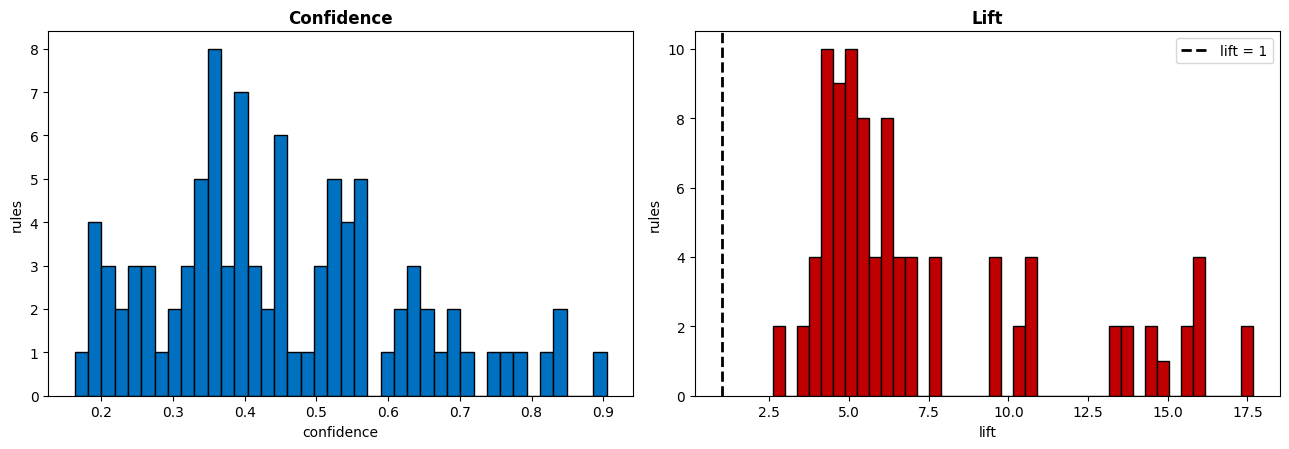

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].hist(rules.confidence, bins=40, color='#0070C0', edgecolor='black')
ax[0].set_xlabel('confidence'); ax[0].set_ylabel('rules')
ax[0].set_title('Confidence', fontweight='bold')

ax[1].hist(rules.lift, bins=40, color='#C00000', edgecolor='black')
ax[1].axvline(1, color='black', ls='--', lw=2, label='lift = 1')
ax[1].set_xlabel('lift'); ax[1].set_ylabel('rules')
ax[1].set_title('Lift', fontweight='bold'); ax[1].legend()
plt.tight_layout(); plt.show()



* On the left, confidence spread across its range.
* On the right, lift, with a dashed line at 1.
* Every single rule sits to the right of that line. Not one has lift below 1.
* That is not luck. It is the support threshold filtering out everything weak before lift sees it.

---
# Section 3: Leverage

```
leverage = P(A and B) - P(A) x P(B)
```

Lift gives a ratio. Leverage gives a count: how many extra baskets above chance.

In [ ]:
rules['extra_baskets'] = rules.leverage * len(B)

print('THE RISK WITH LIFT: a big ratio on a tiny number of baskets')
print()
high_lift = (rules.sort_values('lift', ascending=False)
                  .drop_duplicates(subset='THEN').head(6))
for _, r in high_lift.iterrows():
    print(f'   IF    {r.IF}')
    print(f'   THEN  {r.THEN}')
    print(f'         lift {r.lift:.1f}   support {r.support:.3f}   '
          f'{int(r.support*len(B)):,} baskets   {r.extra_baskets:.0f} extra')
    print()
print()
print('Read the last two columns. A lift of 20 on 40 baskets is less useful')
print('than a lift of 3 on 4,000.')

THE RISK WITH LIFT: a big ratio on a tiny number of baskets

   IF    GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER
   THEN  PINK REGENCY TEACUP AND SAUCER
         lift 17.7   support 0.029   284 baskets   268 extra

   IF    PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER
   THEN  GREEN REGENCY TEACUP AND SAUCER
         lift 17.4   support 0.029   284 baskets   268 extra

   IF    GARDENERS KNEELING PAD CUP OF TEA
   THEN  GARDENERS KNEELING PAD KEEP CALM
         lift 16.0   support 0.024   243 baskets   228 extra

   IF    GARDENERS KNEELING PAD KEEP CALM
   THEN  GARDENERS KNEELING PAD CUP OF TEA
         lift 16.0   support 0.024   243 baskets   228 extra

   IF    SPACEBOY LUNCH BOX
   THEN  DOLLY GIRL LUNCH BOX
         lift 15.8   support 0.023   231 baskets   216 extra

   IF    DOLLY GIRL LUNCH BOX
   THEN  SPACEBOY LUNCH BOX
         lift 15.8   support 0.023   231 baskets   216 extra


Read the last two columns. A lift of 20 on 40 bask

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


* These are the six highest lifts in the whole set.
* The top one reaches 17.7, which is the biggest number on the slide.
* Now check what it rests on. 284 baskets out of 9,938, which is under 3 percent.
* The last column says 268 extra. If the three teacups were unrelated you would expect them together in about 16 baskets. We found 284.
* So lift tells you how strong a pattern is. It does not tell you how many customers it affects.
* A lift of 20 on 40 baskets is worth less than a lift of 3 on 4,000.

---
# Section 4: Conviction

```
conviction = (1 - P(right side)) / (1 - confidence)
```

How often the rule would break if the items were independent, against how often it
actually breaks. High conviction means the rule rarely fails.

In [ ]:
r2 = rules.copy()
r2['conviction'] = (1 - r2['consequent support']) / (1 - r2['confidence']).replace(0, np.nan)

print('THE MOST RELIABLE RULES, BY CONVICTION')
print()
print(f"{'rule':<60}{'conf':>7}{'lift':>7}{'conviction':>12}")
for _, r in r2.sort_values('conviction', ascending=False).head(8).iterrows():
    lab = f'{r.IF[:24]} -> {r.THEN[:26]}'
    cv = 'inf' if pd.isna(r.conviction) else f'{r.conviction:.2f}'
    print(f'{lab:<60}{r.confidence:>7.2f}{r.lift:>7.2f}{cv:>12}')
print()
print('Conviction above 1 means the rule breaks less often than chance predicts.')
print('Infinity means it never breaks, because confidence is exactly 1.')

THE MOST RELIABLE RULES, BY CONVICTION

rule                                                           conf   lift  conviction
PINK REGENCY TEACUP AND  -> GREEN REGENCY TEACUP AND S         0.90  17.42        9.92
GREEN REGENCY TEACUP AND -> ROSES REGENCY TEACUP AND S         0.84  14.72        5.99
PINK REGENCY TEACUP AND  -> GREEN REGENCY TEACUP AND S         0.84  16.11        5.79
GREEN REGENCY TEACUP AND -> ROSES REGENCY TEACUP AND S         0.82  14.39        5.36
PINK REGENCY TEACUP AND  -> ROSES REGENCY TEACUP AND S         0.78  13.61        4.27
GREEN REGENCY TEACUP AND -> ROSES REGENCY TEACUP AND S         0.77  13.40        4.05
REGENCY CAKESTAND 3 TIER -> GREEN REGENCY TEACUP AND S         0.75  14.51        3.84
GREEN REGENCY TEACUP AND -> PINK REGENCY TEACUP AND SA         0.72  17.69        3.39

Conviction above 1 means the rule breaks less often than chance predicts.
Infinity means it never breaks, because confidence is exactly 1.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


* The rule says: pink and roses teacups in the basket, so green should be there too. It breaks when green is missing.
* Confidence is 0.90, so it holds 90 percent of the time. It breaks the other 10 percent.
* Green teacups sit in about 5 percent of baskets. If the rule were meaningless, green would be missing 95 percent of the time.
* If these products had nothing to do with each other, this rule would fail almost every time. In reality it fails one time in ten. So it fails about ten times less often than it would by chance.

---
# Section 5: Chi-squared

```
chi-squared = sum over the four cells of (observed - expected)^2 / expected
expected    = (row total x column total) / N
```

Tests whether the gap between observed and expected is bigger than coincidence
would produce. For a 2x2 table the cutoff at the 5 percent level is **3.84**.

In [ ]:
def chi2_for(A, Bset, basket_df):
    """Build the 2x2 table for one rule and work out chi-squared by hand."""
    n = len(basket_df)
    hasA = basket_df[list(A)].all(axis=1)
    hasB = basket_df[Bset]
    both   = int(( hasA &  hasB).sum())
    a_only = int(( hasA & ~hasB).sum())
    b_only = int((~hasA &  hasB).sum())
    neither= int((~hasA & ~hasB).sum())
    rowA, rowNotA = both + a_only, b_only + neither
    colB, colNotB = both + b_only, a_only + neither
    exp = [rowA*colB/n, rowA*colNotB/n, rowNotA*colB/n, rowNotA*colNotB/n]
    obs = [both, a_only, b_only, neither]
    chi = sum((o-e)**2/e for o, e in zip(obs, exp) if e > 0)
    return obs, exp, chi, n

# take one strong rule and show every step
r = rules.sort_values('lift', ascending=False).iloc[0]
A, Bs = list(r.antecedents), r.THEN
obs, exp, chi, n = chi2_for(A, Bs, B)

print(f'RULE:  {" + ".join(A)}  ->  {Bs}')
print()
print(f'   N = {n:,} baskets')
print()
print(f"   {'cell':<22}{'observed':>10}{'expected':>11}{'(o-e)^2/e':>12}")
for lab, o, e in zip(['A and B', 'A, not B', 'not A, B', 'neither'], obs, exp):
    print(f'   {lab:<22}{o:>10,}{e:>11,.1f}{(o-e)**2/e:>12.2f}')
print()
print(f'   chi-squared = {chi:,.2f}')
print(f'   cutoff at 5% for 1 degree of freedom = 3.84')
print(f'   verdict: {"SIGNIFICANT" if chi > 3.84 else "not significant"}')

RULE:  GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER  ->  PINK REGENCY TEACUP AND SAUCER

   N = 9,938 baskets

   cell                    observed   expected   (o-e)^2/e
   A and B                      284       16.1     4470.74
   A, not B                     112      379.9      188.96
   not A, B                     119      386.9      185.54
   neither                    9,423    9,155.1        7.84

   chi-squared = 4,853.08
   cutoff at 5% for 1 degree of freedom = 3.84
   verdict: SIGNIFICANT


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


* We take one rule and build the 2x2 table, then compute expected counts assuming the products are unrelated.
* Look at the first row. We expected 16 baskets. We found 284.
* That one cell alone contributes 4,470 to the total, because the gap is enormous.
* The total comes to 4,853. The cutoff for a 2x2 table at the 5 percent level is 3.84.
* Compare that against our bread and milk example. There we got 0.31 on five baskets and could never have reached 3.84. Same test, 9,938 baskets instead of 5.

---
# Section 6: All Measures, Side by Side

In [ ]:
summary = sample.copy()
summary['conviction'] = ((1 - summary['consequent support'])
                         / (1 - summary['confidence']).replace(0, np.nan))

cols = ['support', 'confidence', 'lift', 'leverage', 'conviction', 'chi2']
print('HOW THE MEASURES RANK THE SAME RULES')
print()
print(f"{'ranked by':<14}" + ''.join(f'{c[:9]:>11}' for c in cols))
for by in cols:
    tops = set(summary.nlargest(10, by).index)
    row = ''.join(f'{len(tops & set(summary.nlargest(10, c).index)):>11}' for c in cols)
    print(f'{by:<14}{row}')
print()
print('Each cell is how many of the top 10 are shared between two measures.')
print('10 means perfect agreement. Low numbers mean they disagree.')

HOW THE MEASURES RANK THE SAME RULES

ranked by         support  confidenc       lift   leverage  convictio       chi2
support                10          4          2          8          4          4
confidence              4         10          7          5          9          8
lift                    2          7         10          4          8          8
leverage                8          5          4         10          5          6
conviction              4          9          8          5         10          9
chi2                    4          8          8          6          9         10

Each cell is how many of the top 10 are shared between two measures.
10 means perfect agreement. Low numbers mean they disagree.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


* Six measures, and this shows how much they agree on which rules matter.
* Each cell counts how many of the top ten are shared between two measures. Ten means perfect agreement.
* Read the lift row. It shares only 2 of its top ten with support, and 4 with leverage.
* Confidence and conviction agree at 9 and 10, because they are built from the same ratio.
* The point: no single measure is enough. Pick one, state it, and defend it.

---
# Section 7: From Baskets to Sequences

Same data, grouped differently.

- **Baskets** grouped by InvoiceNo. One shopping trip.
- **Sequences** grouped by CustomerID, ordered by InvoiceDate. A whole history.

**CustomerID is missing on about a quarter of rows.** Those rows cannot be placed
in anybody's timeline, so they are dropped here.

In [ ]:
seq_df = df.dropna(subset=['CustomerID']).copy()
seq_df['InvoiceDate'] = pd.to_datetime(seq_df['InvoiceDate'])

print(f'rows with a CustomerID : {len(seq_df):,}  of {len(df):,}')
print(f'customers              : {int(seq_df.CustomerID.nunique()):,}')

# Filter to the kept products FIRST. Doing it inside a groupby lambda
# rebuilds the lookup set once per invoice, which is enormously slower.
common_set = set(common)
seq_df = seq_df[seq_df.Description.isin(common_set)]

visits = (seq_df.groupby(['CustomerID', 'InvoiceNo', 'InvoiceDate'])['Description']
                .agg(frozenset)
                .reset_index())

sequences = {}
for cid, g in visits.sort_values('InvoiceDate').groupby('CustomerID'):
    sequences[cid] = list(g.Description)

multi = {c: s for c, s in sequences.items() if len(s) >= 2}
print(f'customers with 2+ visits: {len(multi):,}')
print(f'average visits          : {np.mean([len(s) for s in multi.values()]):.1f}')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


rows with a CustomerID : 392,732  of 525,462
customers              : 4,339
customers with 2+ visits: 2,449
average visits          : 5.5


In [ ]:
print('THREE CUSTOMER SEQUENCES')
print()
for cid in list(multi)[:3]:
    print(f'   customer {int(cid)}:')
    for i, ev in enumerate(multi[cid], 1):
        items = sorted(ev)
        shown = ', '.join(p[:28] for p in items[:3])
        more = f'  (+{len(items)-3} more)' if len(items) > 3 else ''
        print(f'      visit {i}:  {{{shown}}}{more}')
    print()
print('Angle brackets would wrap the whole thing. Each visit is one itemset.')

THREE CUSTOMER SEQUENCES

   customer 12347:
      visit 1:  {ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE PINK, ALARM CLOCK BAKELIKE RED}  (+2 more)
      visit 2:  {60 TEATIME FAIRY CAKE CASES, ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE PINK}  (+4 more)
      visit 3:  {RED TOADSTOOL LED NIGHT LIGH, REGENCY CAKESTAND 3 TIER, ROSES REGENCY TEACUP AND SAU}
      visit 4:  {ALARM CLOCK BAKELIKE RED, RABBIT NIGHT LIGHT}
      visit 5:  {60 TEATIME FAIRY CAKE CASES, ALARM CLOCK BAKELIKE RED, REGENCY CAKESTAND 3 TIER}  (+1 more)
      visit 6:  {60 TEATIME FAIRY CAKE CASES, ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE PINK}  (+8 more)
      visit 7:  {RABBIT NIGHT LIGHT, RED TOADSTOOL LED NIGHT LIGH, WOODLAND CHARLOTTE BAG}

   customer 12348:
      visit 1:  {60 TEATIME FAIRY CAKE CASES, PACK OF 60 PINK PAISLEY CAKE, POSTAGE}
      visit 2:  {POSTAGE}
      visit 3:  {POSTAGE}
      visit 4:  {POSTAGE}

   customer 12352:
      visit 1:  {DOLLY GIRL LUNCH BOX, HOME BUILDING 

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---
# Section 8: Sequential Patterns, Level by Level

- **L1:** count every single item across customers
- **L2:** build ordered pairs, count them
- **Lk:** extend each pattern by one item, count
- Stop when nothing reaches support

**Support counts customers, not occurrences.**

In [ ]:
SEQ = list(multi.values())
NS = len(SEQ)
MIN_SEQ = 0.02                       # 2% of customers
MIN_COUNT = int(MIN_SEQ * NS)

# Build an index once: for every customer, where does each product appear?
# Scanning every timeline for every candidate pattern is far too slow.
POS = []
for s in SEQ:
    d = {}
    for i, visit in enumerate(s):
        for item in visit:
            d.setdefault(item, []).append(i)
    POS.append(d)

HAS = {}
for c, d in enumerate(POS):
    for item in d:
        HAS.setdefault(item, set()).add(c)

def seq_support(pattern):
    """How many customers contain this pattern, in order, gaps allowed?"""
    cands = HAS.get(pattern[0], set())
    for item in pattern[1:]:
        cands = cands & HAS.get(item, set())
        if not cands:
            return 0
    count = 0
    for c in cands:
        d = POS[c]
        at = -1
        ok = True
        for item in pattern:
            nxt = next((p for p in d[item] if p > at), None)
            if nxt is None:
                ok = False; break
            at = nxt
        if ok:
            count += 1
    return count

print(f'{NS:,} customers with 2+ visits')
print(f'minimum support: {MIN_SEQ:.0%} = {MIN_COUNT} customers')
print(f'index built for {len(HAS):,} products')

2,449 customers with 2+ visits
minimum support: 2% = 48 customers
index built for 100 products


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
items = sorted({p for s in SEQ for ev in s for p in ev})

print('L1: single items')
L1 = [(it, len(cs)) for it, cs in HAS.items() if len(cs) >= MIN_COUNT]
L1.sort(key=lambda t: -t[1])
print(f'   {len(L1)} of {len(items)} items pass')
print()
for it, c in L1[:8]:
    print(f'   {it[:46]:<48}{c:>6} customers  {c/NS*100:>5.1f}%')

L1: single items
   99 of 100 items pass

   REGENCY CAKESTAND 3 TIER                           709 customers   29.0%
   WHITE HANGING HEART T-LIGHT HOLDER                 672 customers   27.4%
   PARTY BUNTING                                      584 customers   23.8%
   ASSORTED COLOUR BIRD ORNAMENT                      545 customers   22.3%
   JUMBO BAG RED RETROSPOT                            544 customers   22.2%
   PACK OF 72 RETROSPOT CAKE CASES                    540 customers   22.0%
   SET OF 3 CAKE TINS PANTRY DESIGN                   528 customers   21.6%
   PAPER CHAIN KIT 50'S CHRISTMAS                     509 customers   20.8%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
base = [it for it, _ in L1]
print(f'L2: {len(base)*(len(base)-1):,} ordered pairs to test')
print()
t0 = time.perf_counter()
L2 = []
for x in base:
    for y in base:
        if x == y: continue
        c = seq_support([x, y])
        if c >= MIN_COUNT:
            L2.append(((x, y), c))
L2.sort(key=lambda t: -t[1])
print(f'   ({time.perf_counter()-t0:.1f}s)')
print(f'   {len(L2):,} pairs pass')
print()
print('THE TEN STRONGEST ORDERED PAIRS')
for (x, y), c in L2[:10]:
    print(f'   {x[:30]:<32} THEN {y[:30]:<32}{c:>5}  {c/NS*100:>5.1f}%')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


L2: 9,702 ordered pairs to test

   (2.0s)
   4,532 pairs pass

THE TEN STRONGEST ORDERED PAIRS
   LUNCH BAG RED RETROSPOT          THEN LUNCH BAG  BLACK SKULL.           212    8.7%
   LUNCH BAG CARS BLUE              THEN LUNCH BAG RED RETROSPOT           209    8.5%
   LUNCH BAG  BLACK SKULL.          THEN LUNCH BAG RED RETROSPOT           208    8.5%
   LUNCH BAG RED RETROSPOT          THEN LUNCH BAG SPACEBOY DESIGN         207    8.5%
   REGENCY CAKESTAND 3 TIER         THEN SET OF 3 REGENCY CAKE TINS        206    8.4%
   LUNCH BAG RED RETROSPOT          THEN LUNCH BAG SUKI DESIGN             203    8.3%
   JUMBO BAG RED RETROSPOT          THEN JUMBO BAG VINTAGE DOILY           201    8.2%
   LUNCH BAG PINK POLKADOT          THEN LUNCH BAG RED RETROSPOT           201    8.2%
   JUMBO BAG RED RETROSPOT          THEN LUNCH BAG RED RETROSPOT           200    8.2%
   PARTY BUNTING                    THEN SPOTTY BUNTING                    198    8.1%


In [ ]:
print('DOES ORDER MATTER? Compare each pair against its reverse.')
print()
d2 = {p: c for p, c in L2}
print(f"{'pattern':<66}{'forward':>9}{'reverse':>9}")
shown = 0
for (x, y), c in L2:
    rev = d2.get((y, x), 0)
    if shown < 8:
        print(f'   {x[:28]:<30} -> {y[:28]:<30}{c:>7}{rev:>9}')
        shown += 1
print()
asym = [((x,y),c) for (x,y),c in L2 if d2.get((y,x),0) == 0]
print(f'Pairs that work in ONE direction only: {len(asym):,} of {len(L2):,}')
if asym:
    print()
    print('The most one-directional:')
    for (x, y), c in asym[:4]:
        print(f'   {x[:30]} THEN {y[:30]}   {c} customers')
        print(f'      the reverse never happens')

DOES ORDER MATTER? Compare each pair against its reverse.

pattern                                                             forward  reverse
   LUNCH BAG RED RETROSPOT        -> LUNCH BAG  BLACK SKULL.           212      208
   LUNCH BAG CARS BLUE            -> LUNCH BAG RED RETROSPOT           209      194
   LUNCH BAG  BLACK SKULL.        -> LUNCH BAG RED RETROSPOT           208      212
   LUNCH BAG RED RETROSPOT        -> LUNCH BAG SPACEBOY DESIGN         207      198
   REGENCY CAKESTAND 3 TIER       -> SET OF 3 REGENCY CAKE TINS        206      117
   LUNCH BAG RED RETROSPOT        -> LUNCH BAG SUKI DESIGN             203      171
   JUMBO BAG RED RETROSPOT        -> JUMBO BAG VINTAGE DOILY           201      121
   LUNCH BAG PINK POLKADOT        -> LUNCH BAG RED RETROSPOT           201      196

Pairs that work in ONE direction only: 1,240 of 4,532

The most one-directional:
   REGENCY CAKESTAND 3 TIER THEN HOT WATER BOTTLE KEEP CALM   137 customers
      the reverse never ha

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
